# 2. Ingeniería de Características (Feature Engineering)

En la ingeniería de características tradicional, solíamos mapear manualmente las columnas categóricas en DataFrames de pandas (por ejemplo, convirtiendo `Sex` de 'male'/'female' a 0/1, o aplicando One-Hot encoding manualmente en archivos intermedios como `data/titanic_feature.csv`).

Sin embargo, este enfoque manual tiene desventajas graves en producción:
- Propensión a errores por inconsistencias de categorías en tiempo real.
- Dificultad para mantener scripts paralelos de preprocesamiento.
- Riesgo de fuga de información (data leakage) al escalar los datos antes del split.

### Enfoque Moderno: Pipelines Automatizados

En lugar de crear archivos de datos preprocesados manualmente, utilizaremos el **ColumnTransformer** y **Pipeline** de `scikit-learn`. Este enfoque tiene grandes ventajas:
1. **Automatización Completa**: Cuando el frontend envía los datos crudos en formato JSON (ej. `Sex='female'`, `Embarked='C'`), el preprocesador empaquetado realiza la codificación One-Hot y el escalamiento estándar automáticamente en memoria.
2. **Previene Fugas**: El escalamiento estándar (`StandardScaler`) calcula la media y la desviación estándar **solo en el conjunto de entrenamiento**, y las aplica al de prueba, garantizando una correcta evaluación.
3. **Código Limpio**: Evita tener que escribir funciones de mapeo personalizadas en la API de Flask, haciendo que `app.py` sea sumamente conciso.

In [1]:
# Demostración del Preprocesamiento del Pipeline
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Cargar los datos limpios
df = pd.read_csv('data/titanic_clean.csv')
X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]

# Definir columnas
numerical_cols = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
categorical_cols = ['Sex', 'Embarked']

# Crear el transformador de columnas
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

# Ajustar y transformar una muestra para ver los resultados mapeados
X_transformed = preprocessor.fit_transform(X)
print("Datos originales (primer registro):")
print(X.iloc[0])
print("\nDatos transformados por el preprocesador (primer registro):\n", X_transformed[0])

Datos originales (primer registro):
Pclass         3
Sex         male
Age         22.0
SibSp          1
Parch          0
Fare        7.25
Embarked       S
Name: 0, dtype: object

Datos transformados por el preprocesador (primer registro):
 [ 0.82737724 -0.56573646  0.43279337 -0.47367361 -0.50244517  0.
  1.          0.          0.          1.        ]


In [1]:

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
df = pd.read_csv('data/titanic_clean.csv')

In [3]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [4]:
X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]

numerical_cols = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

categorical_cols = ['Sex', 'Embarked']

In [5]:
X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


In [6]:
print(df.columns)
print(X.columns)

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked'],
      dtype='str')
Index(['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked'],
      dtype='str')


In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

In [8]:
X_transformed = preprocessor.fit_transform(X)

In [9]:
print("Datos originales (primer registro):")
print(X.iloc[0])

print("\nDatos transformados por el preprocesador (primer registro):")
print(X_transformed[0])

Datos originales (primer registro):
Pclass         3
Sex         male
Age         22.0
SibSp          1
Parch          0
Fare        7.25
Embarked       S
Name: 0, dtype: object

Datos transformados por el preprocesador (primer registro):
[ 0.82737724 -0.56573646  0.43279337 -0.47367361 -0.50244517  0.
  1.          0.          0.          1.        ]


In [10]:
from sklearn.preprocessing import LabelEncoder

# Datos categóricos de ejemplo
animales = ['gato', 'perro', 'pez', 'gato', 'perro']

# Crear una instancia de LabelEncoder
le = LabelEncoder()

# Ajustar y transformar los datos
animales_codificados = le.fit_transform(animales)

# Mostrar los datos codificados
print(animales_codificados)

# Si deseas ver cómo se mapean las etiquetas originales
print(list(le.classes_))

[0 1 2 0 1]
[np.str_('gato'), np.str_('perro'), np.str_('pez')]


In [11]:
label_sex = LabelEncoder()
label_embarked = LabelEncoder()

# Fit and transform on training data
df['Sex'] = label_sex.fit_transform(df['Sex'])
df['Embarked'] = label_embarked.fit_transform(df['Embarked'])

In [12]:
df.sample(5)

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
28,1,3,0,28.0,0,0,7.8792,1
268,1,1,0,58.0,0,1,153.4625,2
485,0,3,0,28.0,3,1,25.4667,2
335,0,3,1,28.0,0,0,7.8958,2
426,1,2,0,28.0,1,0,26.0000,2


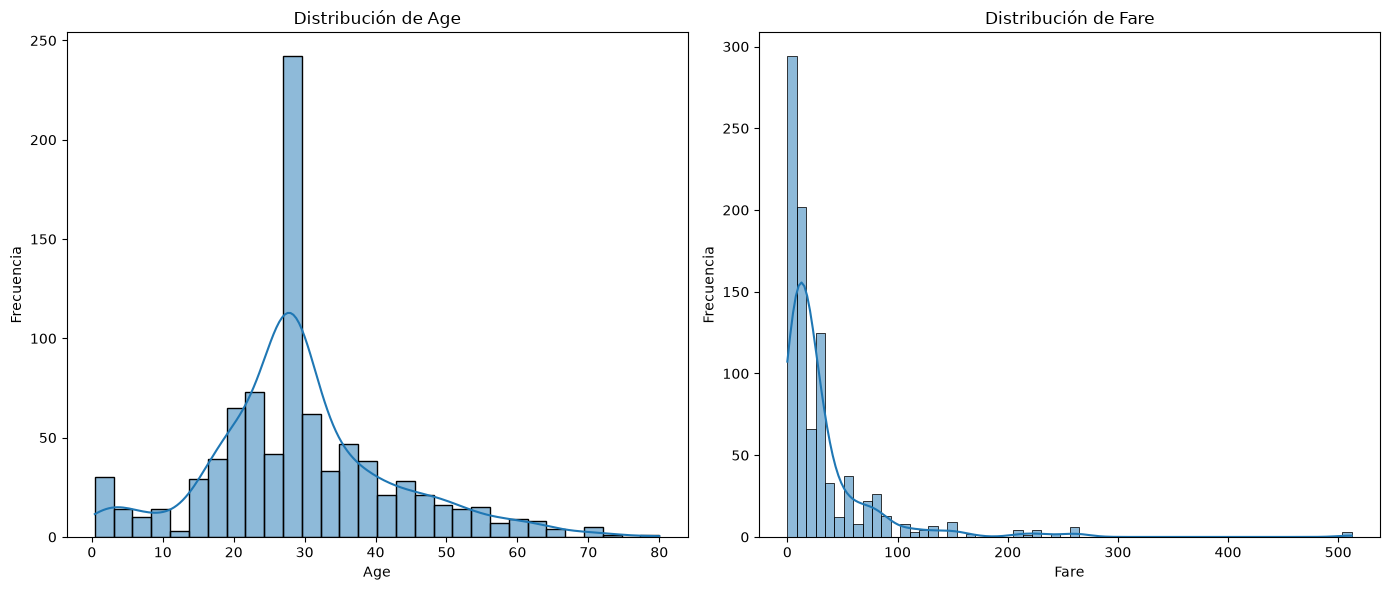

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.histplot(df['Age'].dropna(), kde=True, ax=axes[0])
axes[0].set_title('Distribución de Age')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Frecuencia')

# Gráfica de la distribución de Fare
sns.histplot(df['Fare'].dropna(), kde=True, ax=axes[1])
axes[1].set_title('Distribución de Fare')
axes[1].set_xlabel('Fare')
axes[1].set_ylabel('Frecuencia')

# Mostrar las gráficas
plt.tight_layout()
plt.show()

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import pandas as pd

df = pd.read_csv('data/titanic_clean.csv')

df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [5]:
y = df['Survived']

y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [10]:
X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]

X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [13]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (712, 7)
X_test: (179, 7)
y_train: (712,)
y_test: (179,)


In [14]:
df[['Survived', 'Pclass', 'Sex', 'Age', 'Fare', 'Embarked']].head()

,Survived,Pclass,Sex,Age,Fare,Embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


In [15]:
from sklearn.preprocessing import QuantileTransformer

In [16]:
qun_tra_age = QuantileTransformer(
    output_distribution='normal',
    n_quantiles=500
)

qun_tra_fare = QuantileTransformer(
    output_distribution='normal',
    n_quantiles=500
)

In [17]:
df['Age'] = qun_tra_age.fit_transform(df[['Age']])

df['Fare'] = qun_tra_fare.fit_transform(df[['Fare']])

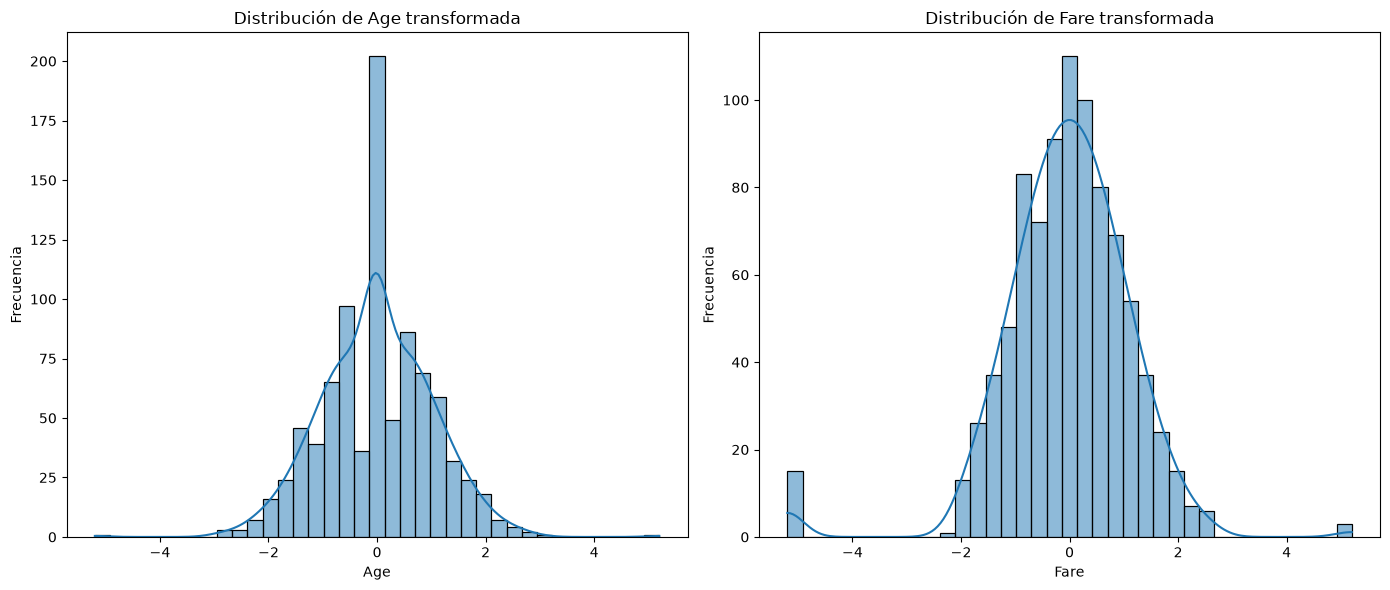

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.histplot(df['Age'].dropna(), kde=True, ax=axes[0])
axes[0].set_title('Distribución de Age transformada')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Frecuencia')

sns.histplot(df['Fare'].dropna(), kde=True, ax=axes[1])
axes[1].set_title('Distribución de Fare transformada')
axes[1].set_xlabel('Fare')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

In [19]:
from sklearn.preprocessing import MinMaxScaler

In [27]:
mms_pclass = MinMaxScaler()
mms_sex = MinMaxScaler()
mms_age = MinMaxScaler()
mms_sibsp = MinMaxScaler()
mms_parch = MinMaxScaler()
mms_fare = MinMaxScaler()
mms_embarked = MinMaxScaler()

In [28]:
# Ejecutar transformaciones
df['Pclass'] = mms_pclass.fit_transform(df[['Pclass']])
df['Sex'] = mms_sex.fit_transform(df[['Sex']])
df['Age'] = mms_age.fit_transform(df[['Age']])
df['SibSp'] = mms_sibsp.fit_transform(df[['SibSp']])
df['Parch'] = mms_parch.fit_transform(df[['Parch']])
df['Fare'] = mms_fare.fit_transform(df[['Fare']])
df['Embarked'] = mms_embarked.fit_transform(df[['Embarked']])

In [22]:
df = pd.read_csv('data/titanic_clean.csv')

df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [23]:
from sklearn.preprocessing import LabelEncoder

le_sex = LabelEncoder()
le_embarked = LabelEncoder()

df['Sex'] = le_sex.fit_transform(df['Sex'])
df['Embarked'] = le_embarked.fit_transform(df['Embarked'])

In [24]:
df[['Sex', 'Embarked']].head()

,Sex,Embarked
0,1,2
1,0,0
2,0,2
3,0,2
4,1,2


In [25]:
print("Sex:", dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_))))
print("Embarked:", dict(zip(le_embarked.classes_, le_embarked.transform(le_embarked.classes_))))

Sex: {'female': np.int64(0), 'male': np.int64(1)}
Embarked: {'C': np.int64(0), 'Q': np.int64(1), 'S': np.int64(2)}


In [26]:
qun_tra_age = QuantileTransformer(
    output_distribution='normal',
    n_quantiles=500
)

qun_tra_fare = QuantileTransformer(
    output_distribution='normal',
    n_quantiles=500
)

df['Age'] = qun_tra_age.fit_transform(df[['Age']])
df['Fare'] = qun_tra_fare.fit_transform(df[['Fare']])

In [29]:
mms_pclass = MinMaxScaler()
mms_sex = MinMaxScaler()
mms_age = MinMaxScaler()
mms_sibsp = MinMaxScaler()
mms_parch = MinMaxScaler()
mms_fare = MinMaxScaler()
mms_embarked = MinMaxScaler()

# Ejecutar transformaciones
df['Pclass'] = mms_pclass.fit_transform(df[['Pclass']])
df['Sex'] = mms_sex.fit_transform(df[['Sex']])
df['Age'] = mms_age.fit_transform(df[['Age']])
df['SibSp'] = mms_sibsp.fit_transform(df[['SibSp']])
df['Parch'] = mms_parch.fit_transform(df[['Parch']])
df['Fare'] = mms_fare.fit_transform(df[['Fare']])
df['Embarked'] = mms_embarked.fit_transform(df[['Embarked']])

In [30]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,1.0,1.0,0.433152,0.125,0.0,0.368146,1.0
1,1,0.0,0.0,0.579431,0.125,0.0,0.615097,0.0
2,1,1.0,0.0,0.462346,0.000,0.0,0.438286,1.0
3,1,0.0,0.0,0.563806,0.125,0.0,0.595112,1.0
4,0,1.0,1.0,0.563806,0.000,0.0,0.448347,1.0


In [31]:
df.drop(columns=['Survived']).agg(['min', 'max'])

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [32]:
df.drop(columns=['Survived']).agg(['min', 'max'])

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [33]:
df['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [3]:
df_original = pd.read_csv('data/titanic_clean.csv')

df_original.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [2]:
import pandas as pd

In [4]:
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    str    
 3   Age       891 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  891 non-null    str    
dtypes: float64(2), int64(4), str(2)
memory usage: 55.8 KB


In [5]:
y = df_original['Survived']

X = df_original.drop(columns=['Survived'])

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (891, 7)
Dimensiones de y: (891,)


In [6]:
print("Valores de Sex:")
print(X['Sex'].value_counts())

print("\nValores de Embarked:")
print(X['Embarked'].value_counts())

Valores de Sex:
Sex
male      577
female    314
Name: count, dtype: int64

Valores de Embarked:
Embarked
S    646
C    168
Q     77
Name: count, dtype: int64


In [7]:
X_encoded = pd.get_dummies(
    X,
    columns=['Sex', 'Embarked'],
    dtype=int
)

X_encoded.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,0,1,0,0,1
1,1,38.0,1,0,71.2833,1,0,1,0,0
2,3,26.0,0,0,7.9250,1,0,0,0,1
3,1,35.0,1,0,53.1000,1,0,0,0,1
4,3,35.0,0,0,8.0500,0,1,0,0,1


In [8]:
X_encoded.shape

(891, 10)

In [9]:
X_encoded.dtypes

Pclass          int64
Age           float64
SibSp           int64
Parch           int64
Fare          float64
Sex_female      int64
Sex_male        int64
Embarked_C      int64
Embarked_Q      int64
Embarked_S      int64
dtype: object

In [10]:
X_encoded.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,0,1,0,0,1
1,1,38.0,1,0,71.2833,1,0,1,0,0
2,3,26.0,0,0,7.9250,1,0,0,0,1
3,1,35.0,1,0,53.1000,1,0,0,0,1
4,3,35.0,0,0,8.0500,0,1,0,0,1


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (712, 10)
X_test: (179, 10)
y_train: (712,)
y_test: (179,)


In [12]:
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
Pclass,712.0,2.308989,0.833563,1.00,2.0000,3.0000,3.0,3.0000
Age,712.0,29.459860,13.034574,0.42,22.0000,28.0000,36.0,80.0000
SibSp,712.0,0.492978,1.060720,0.00,0.0000,0.0000,1.0,8.0000
Parch,712.0,0.390449,0.838134,0.00,0.0000,0.0000,0.0,6.0000
Fare,712.0,31.819826,48.059104,0.00,7.8958,14.4542,31.0,512.3292
Sex_female,712.0,0.355337,0.478952,0.00,0.0000,0.0000,1.0,1.0000
Sex_male,712.0,0.644663,0.478952,0.00,0.0000,1.0000,1.0,1.0000
Embarked_C,712.0,0.195225,0.396652,0.00,0.0000,0.0000,0.0,1.0000
Embarked_Q,712.0,0.077247,0.267171,0.00,0.0000,0.0000,0.0,1.0000
Embarked_S,712.0,0.727528,0.445544,0.00,0.0000,1.0000,1.0,1.0000


In [13]:
from sklearn.preprocessing import QuantileTransformer, MinMaxScaler

In [14]:
import numpy as np

qt_age = QuantileTransformer(
    output_distribution='normal',
    n_quantiles=500,
    random_state=42
)

qt_fare = QuantileTransformer(
    output_distribution='normal',
    n_quantiles=500,
    random_state=42
)

X_train = X_train.copy()
X_test = X_test.copy()

X_train['Age'] = qt_age.fit_transform(X_train[['Age']]).ravel()
X_test['Age'] = qt_age.transform(X_test[['Age']]).ravel()

X_train['Fare'] = qt_fare.fit_transform(X_train[['Fare']]).ravel()
X_test['Fare'] = qt_fare.transform(X_test[['Fare']]).ravel()

In [15]:
columnas_numericas = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

mms = MinMaxScaler()

X_train[columnas_numericas] = mms.fit_transform(
    X_train[columnas_numericas]
)

X_test[columnas_numericas] = mms.transform(
    X_test[columnas_numericas]
)

In [16]:
X_train[columnas_numericas].agg(['min', 'max'])

,Pclass,Age,SibSp,Parch,Fare
min,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0


In [17]:
X_test[columnas_numericas].agg(['min', 'max'])

,Pclass,Age,SibSp,Parch,Fare
min,0.0,0.233733,0.0,0.000000,0.0
max,1.0,0.740238,1.0,0.333333,1.0


In [18]:
train_procesado = X_train.copy()
train_procesado['Survived'] = y_train

test_procesado = X_test.copy()
test_procesado['Survived'] = y_test

df_procesado = pd.concat(
    [train_procesado, test_procesado]
).sort_index()

df_procesado.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Survived
0,1.0,0.434681,0.125,0.0,0.371762,0,1,0,0,1,0
1,0.0,0.576082,0.125,0.0,0.614919,1,0,1,0,0,1
2,1.0,0.461563,0.000,0.0,0.439174,1,0,0,0,1,1
3,0.0,0.560237,0.125,0.0,0.595112,1,0,0,0,1,1
4,1.0,0.560237,0.000,0.0,0.449460,0,1,0,0,1,0


In [19]:
df_procesado.shape

(891, 11)

In [20]:
df_procesado.to_csv(
    './data/titanic_procesado.csv',
    index=False
)

In [21]:
df_verificacion = pd.read_csv('./data/titanic_procesado.csv')

print(df_verificacion.shape)
print(df_verificacion.columns.tolist())

(891, 11)
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Survived']
